In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
bts_sample_path = '../BTS_ZTF.csv'

In [3]:
with open(bts_sample_path, 'r') as file:
    sample = file.readlines()

In [4]:
headers = sample[0].strip().split(',')
headers

['ZTFID',
 'IAUID',
 'RA',
 'Dec',
 'peakt',
 'peakfilt',
 'peakmag',
 'peakabs',
 'duration',
 'rise',
 'fade',
 'type',
 'redshift',
 'b',
 'A_V']

In [5]:
sn_per_type = dict()
times_per_type = dict()
rise_per_type = dict()
fade_per_type = dict()
# times_upper_per_type = dict()
# times_lower_per_type = dict()

for sn in sample[1:]:
    values = sn.strip().split(',')
    sn_type = values[headers.index('type')]
    duration = values[headers.index('duration')]
    rise =  values[headers.index('rise')]
    fade = values[headers.index('fade')]
    if sn_type not in sn_per_type.keys():
        sn_per_type[sn_type] = [values]
    else:
         sn_per_type[sn_type].append(values)
    #time
    # if '>' in duration:
        # times_lower_per_type[sn_typpe]

    
    if sn_type not in times_per_type.keys():
        if '>' not in duration and '<' not in duration:
            times_per_type[sn_type] = [float(duration)]
            rise_per_type[sn_type] = [float(rise)]
            fade_per_type[sn_type] = [float(fade)]
    else:
        if '>' not in duration and '<' not in duration:
            times_per_type[sn_type].append(float(duration))
            rise_per_type[sn_type].append(float(rise))
            fade_per_type[sn_type].append(float(fade))

In [6]:
#get types distirbution

In [7]:
#get times per time distribution

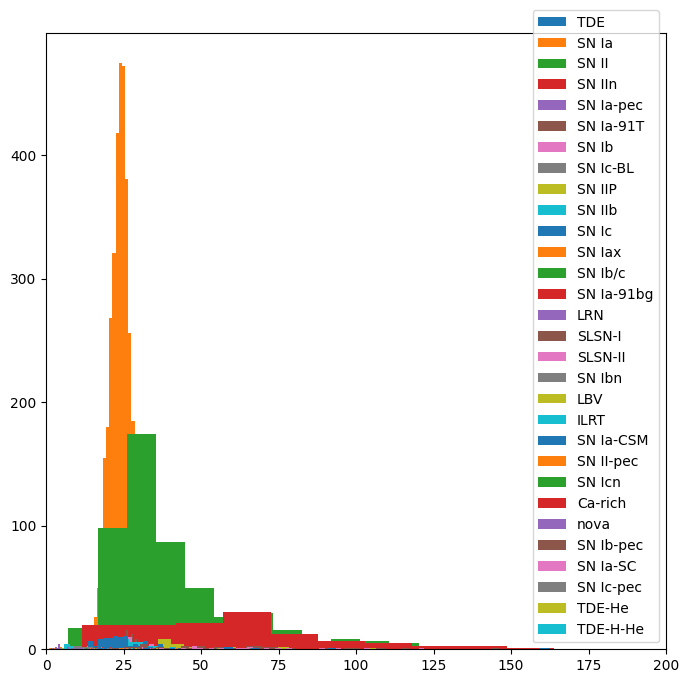

In [8]:
fig = plt.figure(figsize=(8,8))

for key in times_per_type.keys():
    if key != '-' and key != 'other' and key != 'Other':
        plt.hist(times_per_type[key], label=key, bins=50)
    
plt.legend()
plt.xlim(0, 200)
plt.show()

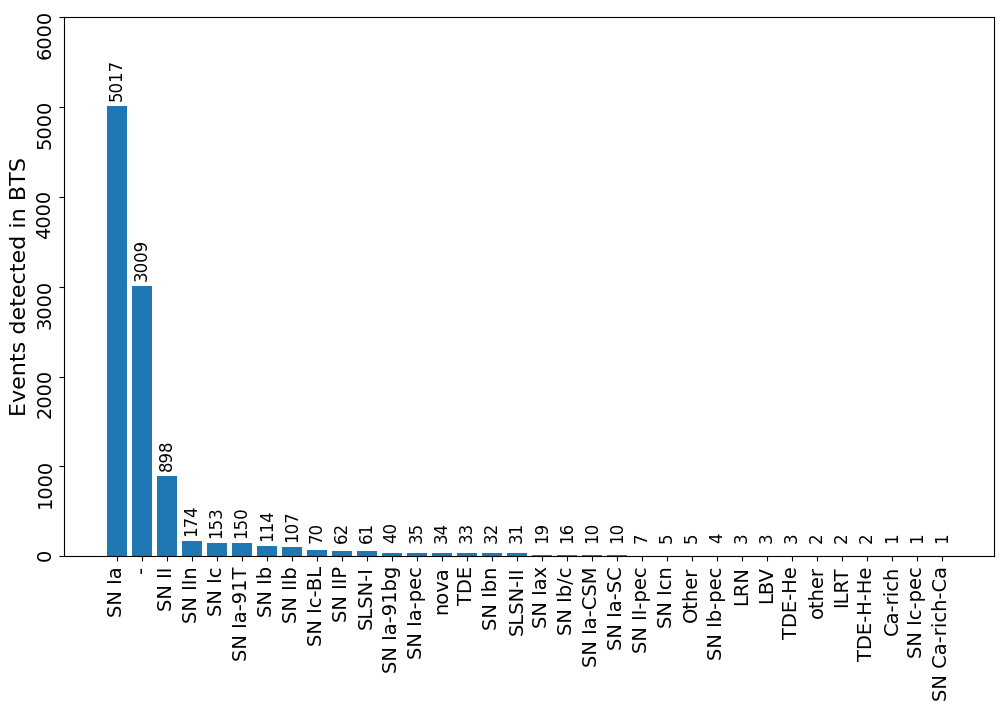

In [9]:
types = [key for key in sn_per_type.keys()]# if key != '-'] #and key != 'other' and key != 'Other']
quantity = [len(sn_per_type[key]) for key in sn_per_type.keys()]#if key != '-'] #and key != 'other' and key != 'Other']
total_sn = np.sum(np.array([len(sn_per_type[key]) for key in sn_per_type.keys()]))


def sort_func(tup):
    return tup[1]
    
list_zipped = list(zip(types, quantity))
list_zipped.sort(reverse=True, key=sort_func)
sort_types, sort_quantity = list(zip(*list_zipped))

fig = plt.figure(figsize=(12,7))

graph = plt.bar(sort_types, sort_quantity, orientation=u'vertical')

#percentages
# plt.text(0.5, 1000, 'hi')

for p, key in zip(graph, sort_types):
    width = p.get_width()
    height = p.get_height()
    x, y = p.get_xy()
    
    plt.text(x + width / 2,
             max(y + height + 100, 200),
             f'{len(sn_per_type[key])}', # / total_sn:.4f}%',
             ha='center',
            rotation=90,
            fontsize=12)

plt.xticks(rotation=90, fontsize=14)
plt.yticks(fontsize=14, rotation=90)
plt.ylabel('Events detected in BTS', fontsize=16)
plt.ylim(0,6000)
# plt.savefig('plots/BTS_ratios.png', bbox_inches='tight')
plt.show()


If I now group them by type:

In [20]:
sn_Ia = [sn for sn in sn_per_type.keys() if 'SN Ia' in sn]
sn_Ibc = [sn for sn in sn_per_type.keys() if 'SN Ib' in sn or 'SN Ic' in sn]
sn_II = [sn for sn in sn_per_type.keys() if 'SN II' in sn]
TDE = [sn for sn in sn_per_type.keys() if 'TDE' in sn]

print('SN Ia types: ', sn_Ia)
print('SN Ibc types: ', sn_Ibc)
print('SN II types: ', sn_II)
print("TDEE types: ", TDE)


total_Ibc, total_II = [], []
for key in sn_Ibc:
    total_Ibc.extend(sn_per_type[key])
for key in sn_II:
    total_II.extend(sn_per_type[key])

total_CC = total_Ibc + total_II

print('N_CC: ', len(total_CC))
print('N_Ibc: ', len(total_Ibc), ' N_ibc / N_cc = ', len(total_Ibc) / len(total_CC))
print('N_II: ', len(total_II), ' N_II / N_cc = ', len(total_II) / len(total_CC))

# sn_per_type[total_CC[0]]

SN Ia types:  ['SN Ia', 'SN Ia-pec', 'SN Ia-91T', 'SN Ia-91bg', 'SN Iax', 'SN Ia-CSM', 'SN Ia-SC']
SN Ibc types:  ['SN Ib', 'SN Ic-BL', 'SN Ic', 'SN Ib/c', 'SN Ibn', 'SN Icn', 'SN Ib-pec', 'SN Ic-pec']
SN II types:  ['SN II', 'SN IIn', 'SN IIP', 'SN IIb', 'SN II-pec']
TDEE types:  ['TDE', 'TDE-He', 'TDE-H-He']
N_CC:  1643
N_Ibc:  395  N_ibc / N_cc =  0.2404138770541692
N_II:  1248  N_II / N_cc =  0.7595861229458308


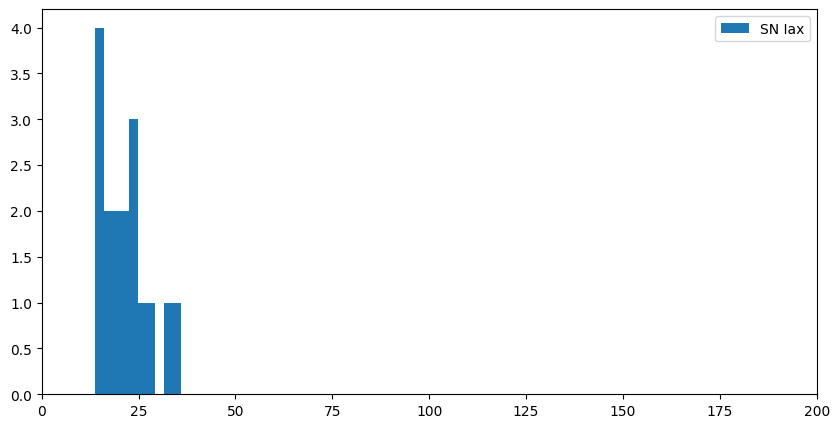

In [15]:
fig = plt.figure(figsize=(10,5))

for key in ['SN Iax']:
    if key != '-' and key != 'other' and key != 'Other':
        plt.hist(times_per_type[key], label=key)
    
plt.legend()
plt.xlim(0, 200)
plt.show()

In [16]:
sn_Ia = [sn for sn in times_per_type.keys() if 'SN Ia' in sn]
sn_Ib = [sn for sn in times_per_type.keys() if 'SN Ib' in sn]
sn_II = [sn for sn in times_per_type.keys() if 'SN II' in sn]
TDE = [sn for sn in times_per_type.keys() if 'TDE' in sn]
all_SN = [sn for sn in times_per_type.keys() if 'SN' in sn]
all_SN_times = []
all_SN_fade = []
all_SN_rise = []
for key in all_SN:
    all_SN_times.extend(times_per_type[key])
    all_SN_fade.extend(rise_per_type[key])
    all_SN_rise.extend(fade_per_type[key])

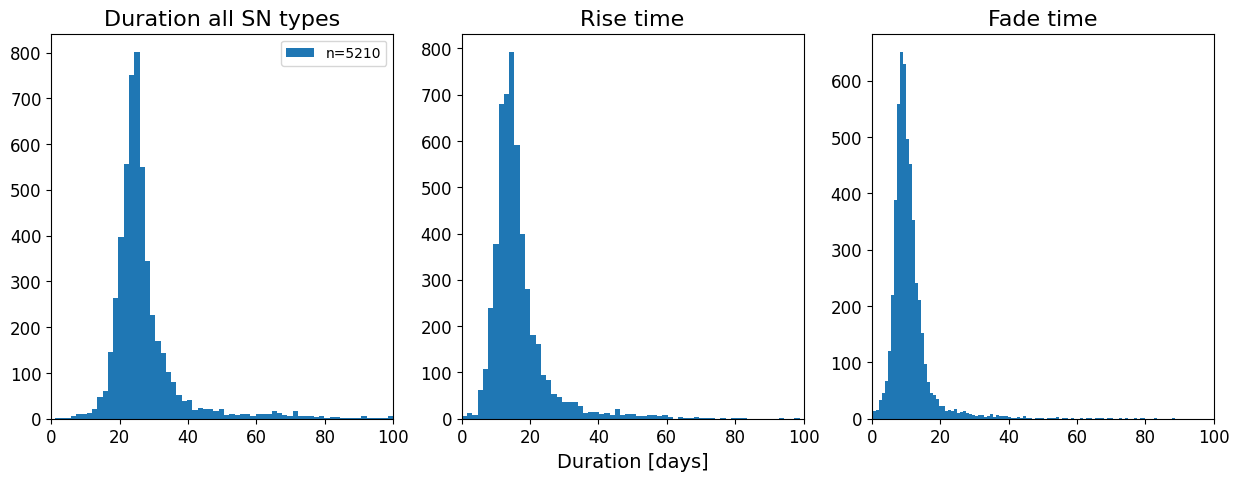

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(15,5))
ax[0].hist(all_SN_times, bins=500, label=f'n={len(all_SN_times)}')
ax[1].hist(all_SN_rise, bins=500)
ax[2].hist(all_SN_fade, bins=500)

ax[0].set_title('Duration all SN types', fontsize=16)
ax[1].set_title('Rise time', fontsize=16)
ax[2].set_title('Fade time', fontsize=16)
    
ax[1].set_xlabel('Duration [days]', fontsize=14)
ax[0].legend()
for i in range(3):
    ax[i].set_xlim(0, 100)
    ax[i].tick_params(labelsize=12)
plt.show()

#test -5 t to t_0 + duration
#make duration vs peak luminosity plot. Key characteristic for clasification, reproduce.  

In [18]:
headers

['ZTFID',
 'IAUID',
 'RA',
 'Dec',
 'peakt',
 'peakfilt',
 'peakmag',
 'peakabs',
 'duration',
 'rise',
 'fade',
 'type',
 'redshift',
 'b',
 'A_V']

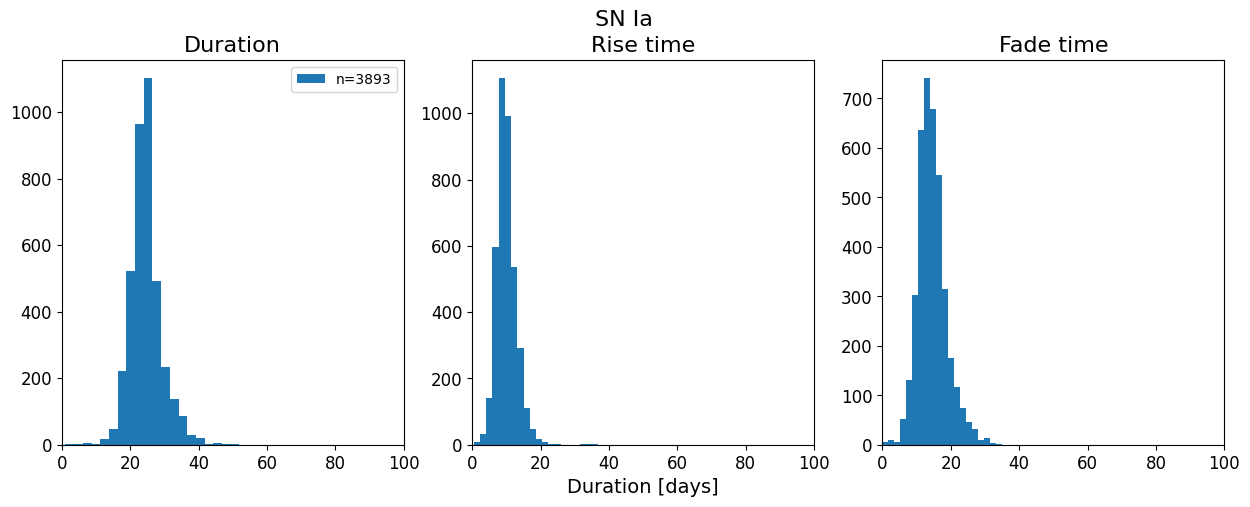

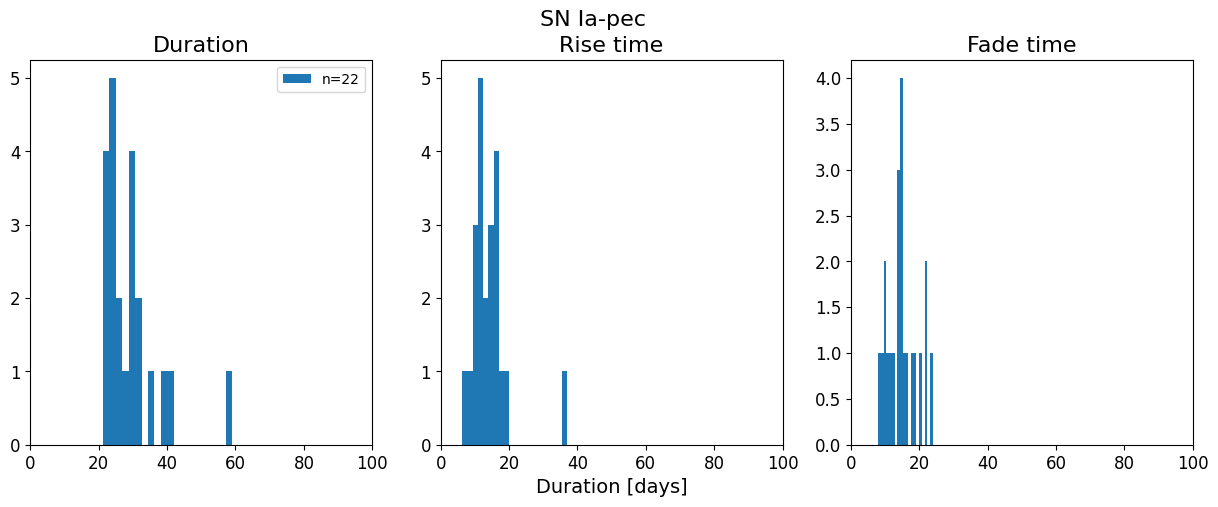

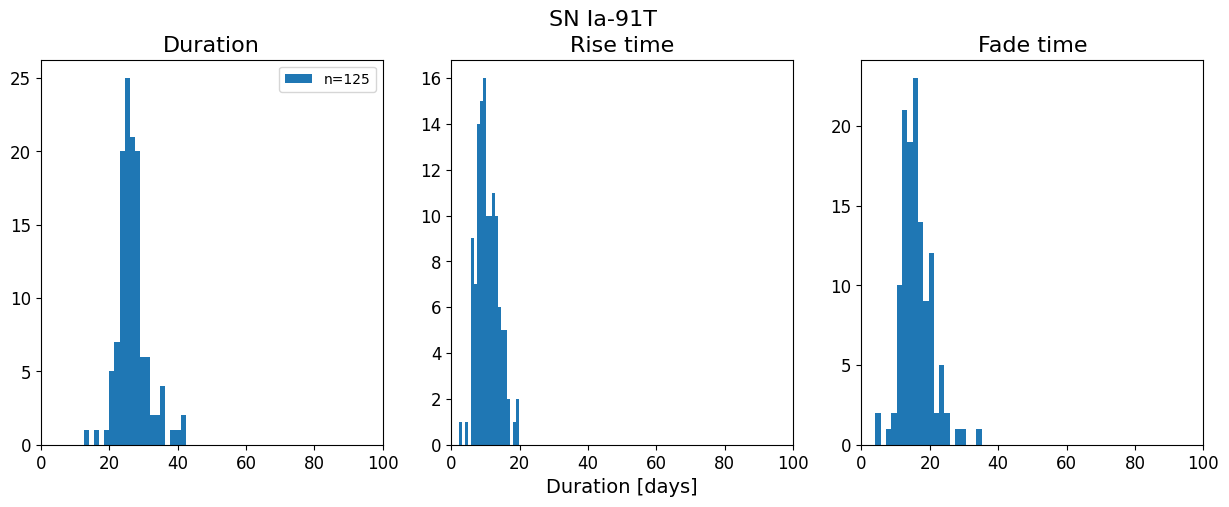

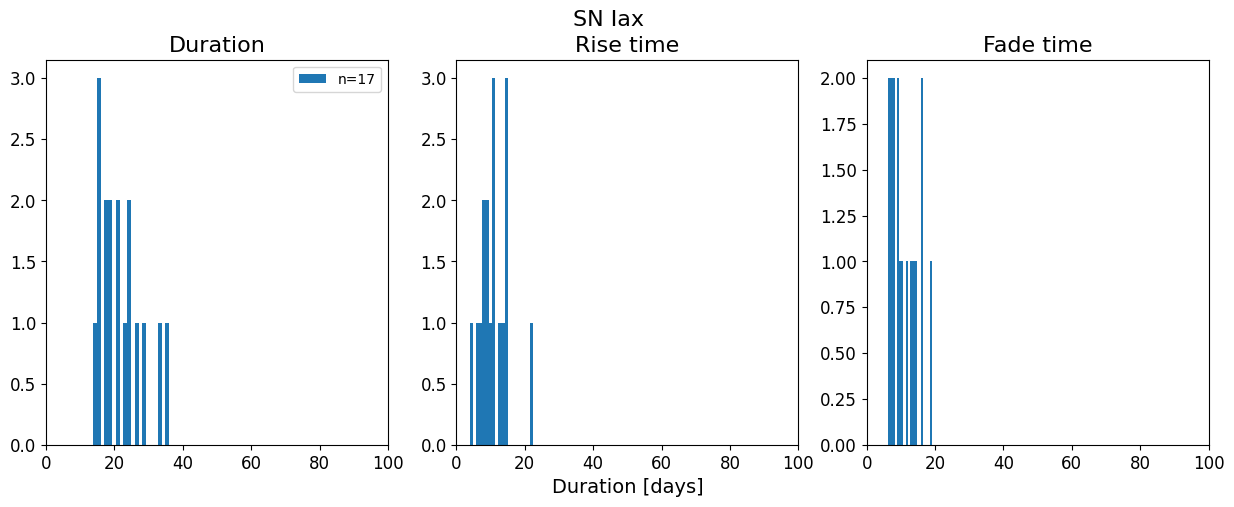

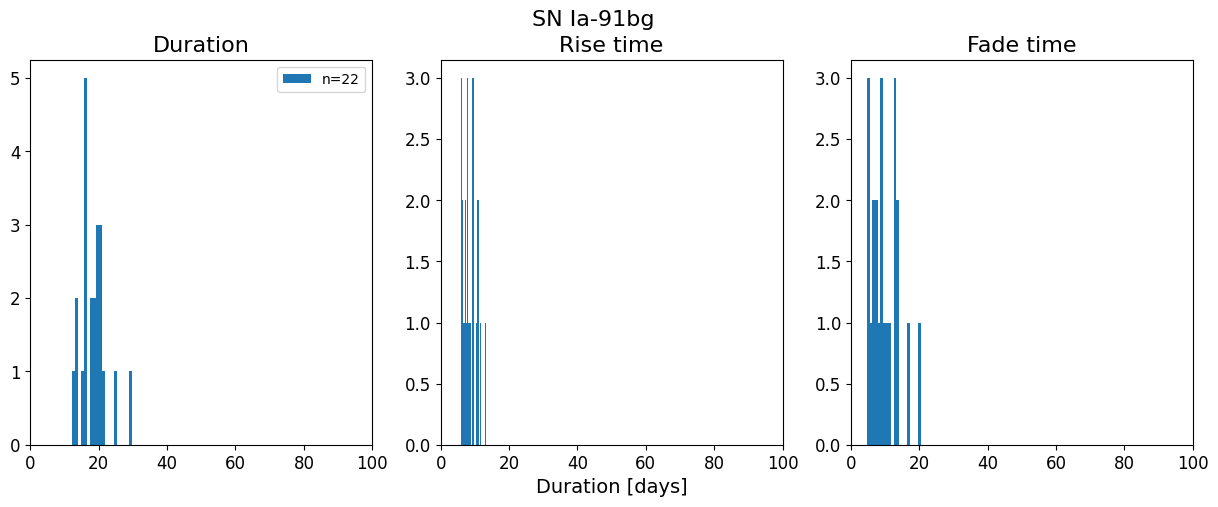

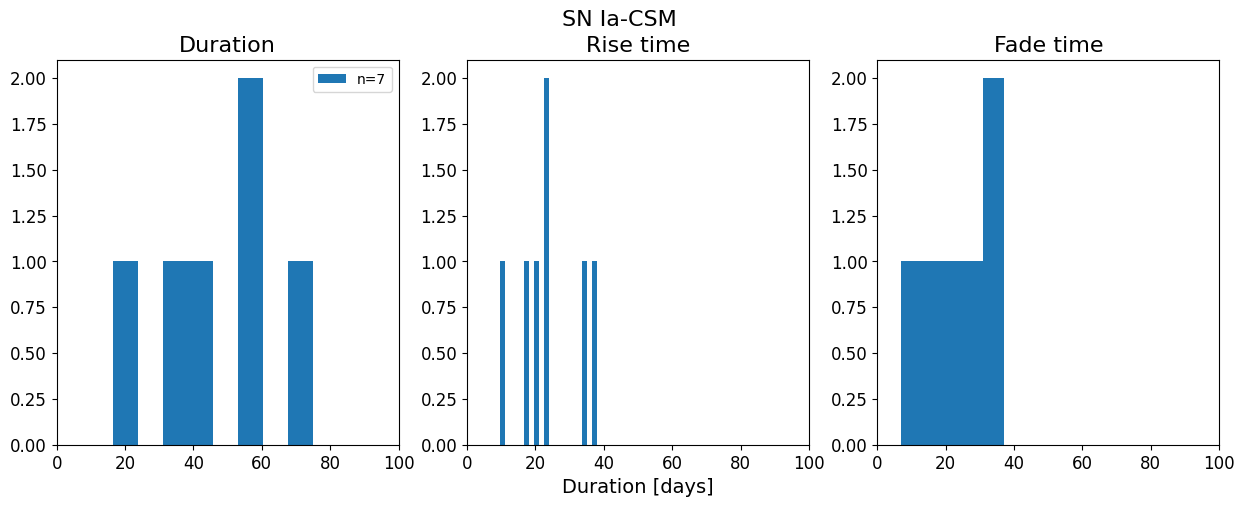

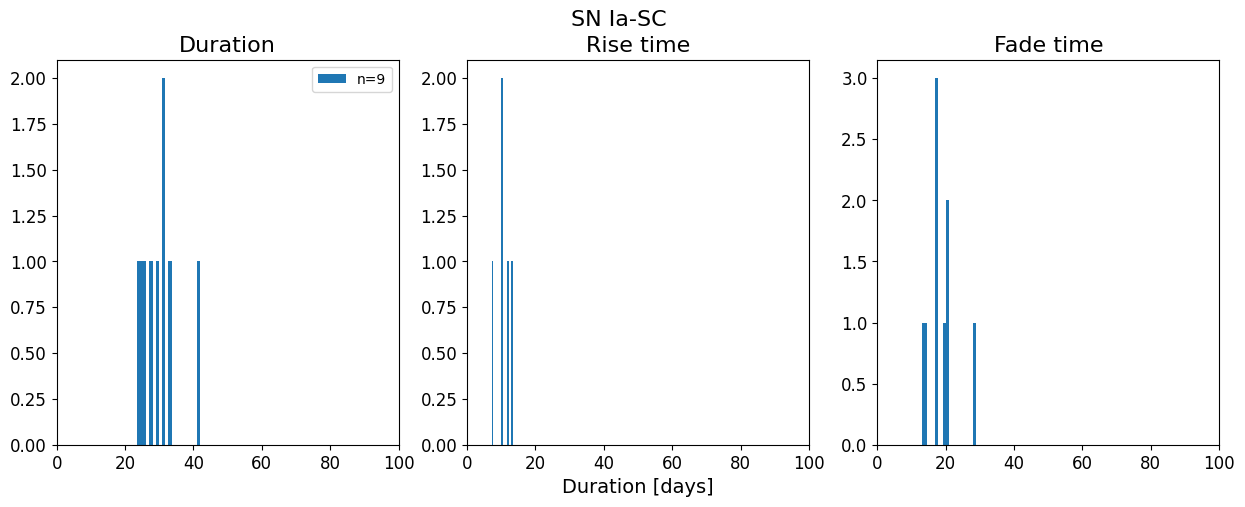

In [19]:
for key in sn_Ia:
    # plt.hist(times_per_type[key], bins=20, label=f'n={len(times_per_type[key])}')
    # plt.title(key, fontsize=16)
    # plt.legend()
    
    # plt.show()
    nbins = 20
    fig, ax = plt.subplots(1, 3, figsize=(15,5))
    ax[0].hist(times_per_type[key], bins=nbins, label=f'n={len(times_per_type[key])}')
    ax[1].hist(rise_per_type[key], bins=nbins)
    ax[2].hist(fade_per_type[key], bins=nbins)
    
    ax[0].set_title('Duration', fontsize=16)
    ax[1].set_title('Rise time', fontsize=16)
    ax[2].set_title('Fade time', fontsize=16)
        
    ax[1].set_xlabel('Duration [days]', fontsize=14)
    ax[0].legend()
    for i in range(3):
        ax[i].set_xlim(0, 100)
        ax[i].tick_params(labelsize=12)
    plt.suptitle(key, fontsize=16)
    plt.show()



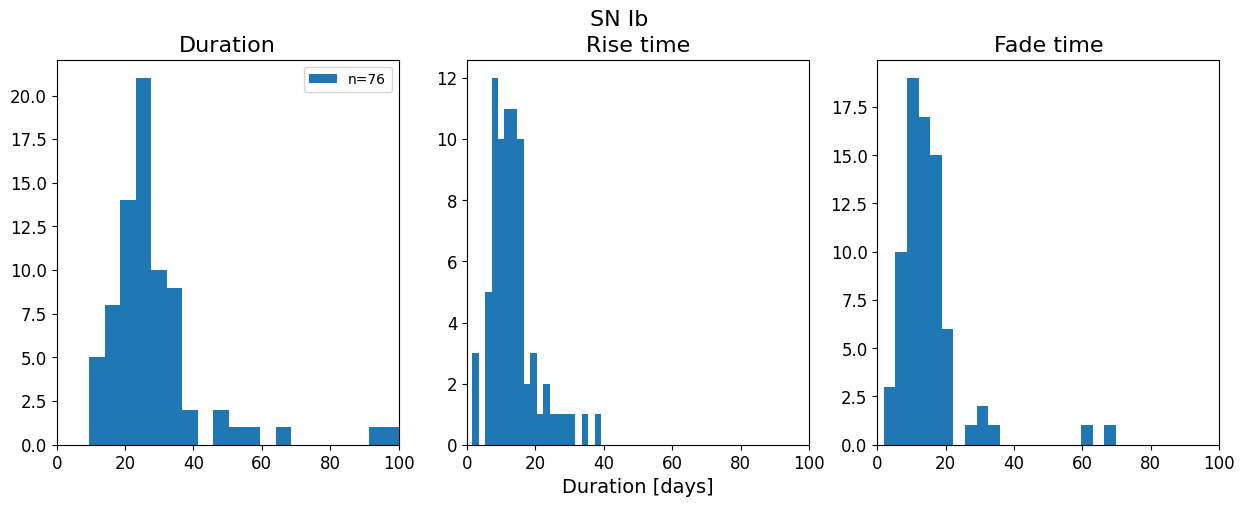

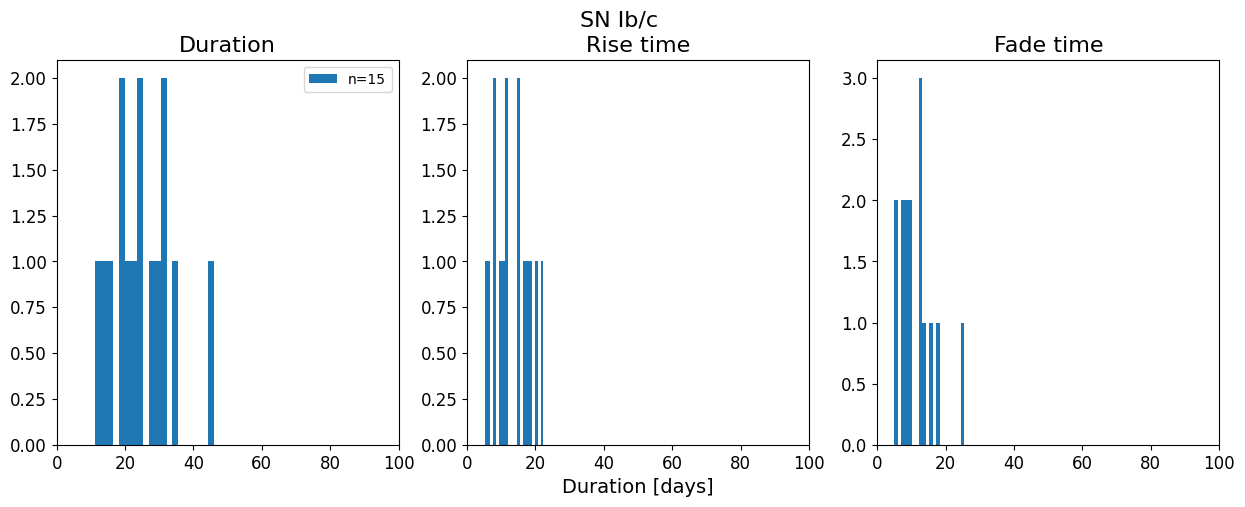

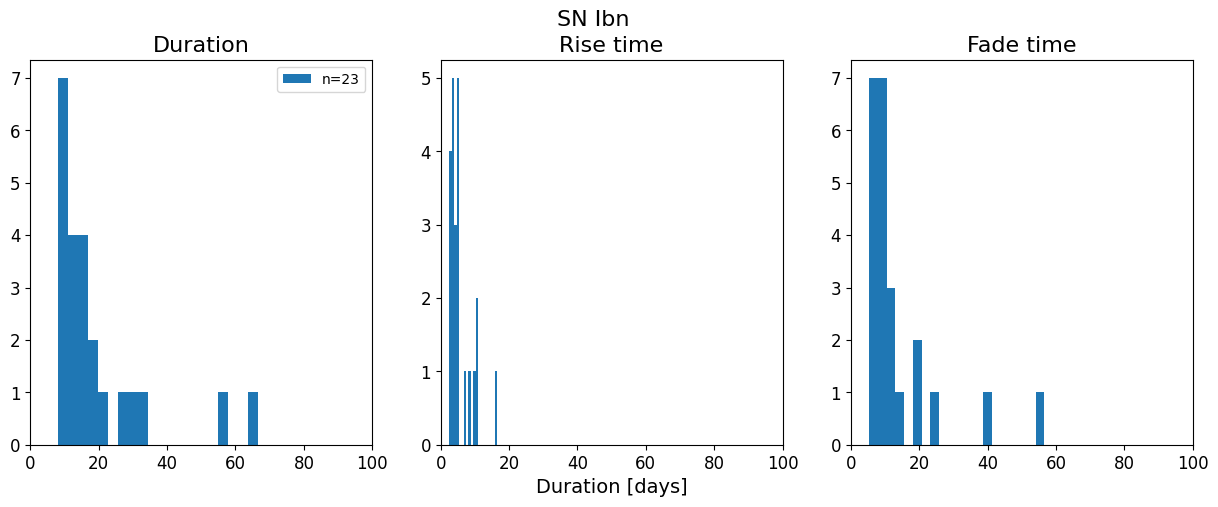

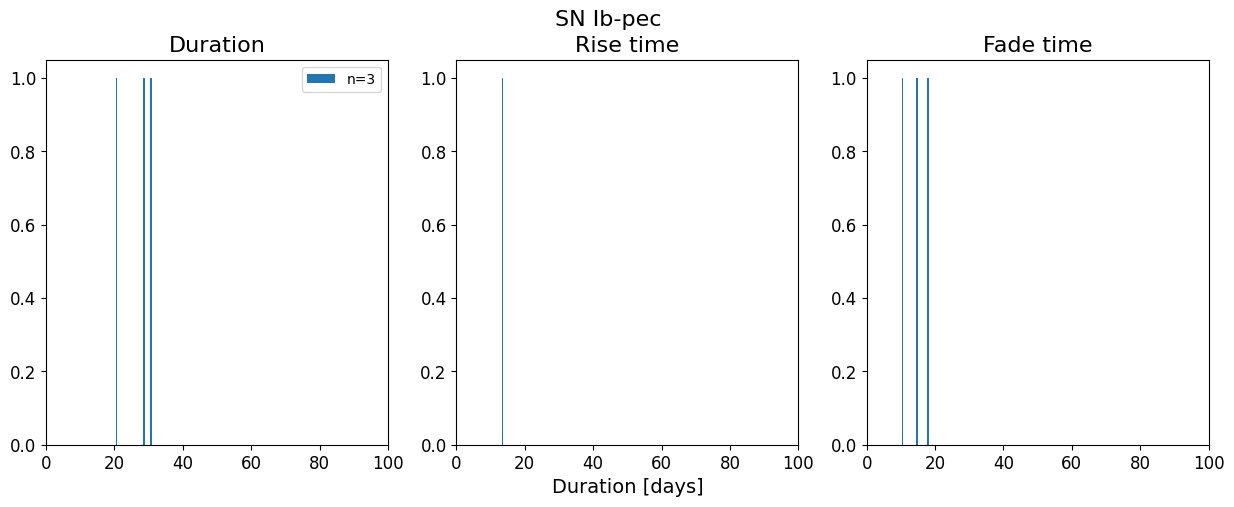

In [20]:
for key in sn_Ib:
    # plt.hist(times_per_type[key],label=f'n={len(times_per_type[key])}')
    # plt.title(key, fontsize=16)
    # plt.legend()
    # plt.show()
    nbins = 20
    fig, ax = plt.subplots(1, 3, figsize=(15,5))
    ax[0].hist(times_per_type[key], bins=nbins, label=f'n={len(times_per_type[key])}')
    ax[1].hist(rise_per_type[key], bins=nbins)
    ax[2].hist(fade_per_type[key], bins=nbins)
    
    ax[0].set_title('Duration', fontsize=16)
    ax[1].set_title('Rise time', fontsize=16)
    ax[2].set_title('Fade time', fontsize=16)
        
    ax[1].set_xlabel('Duration [days]', fontsize=14)
    ax[0].legend()
    for i in range(3):
        ax[i].set_xlim(0, 100)
        ax[i].tick_params(labelsize=12)
    plt.suptitle(key, fontsize=16)
    plt.show()

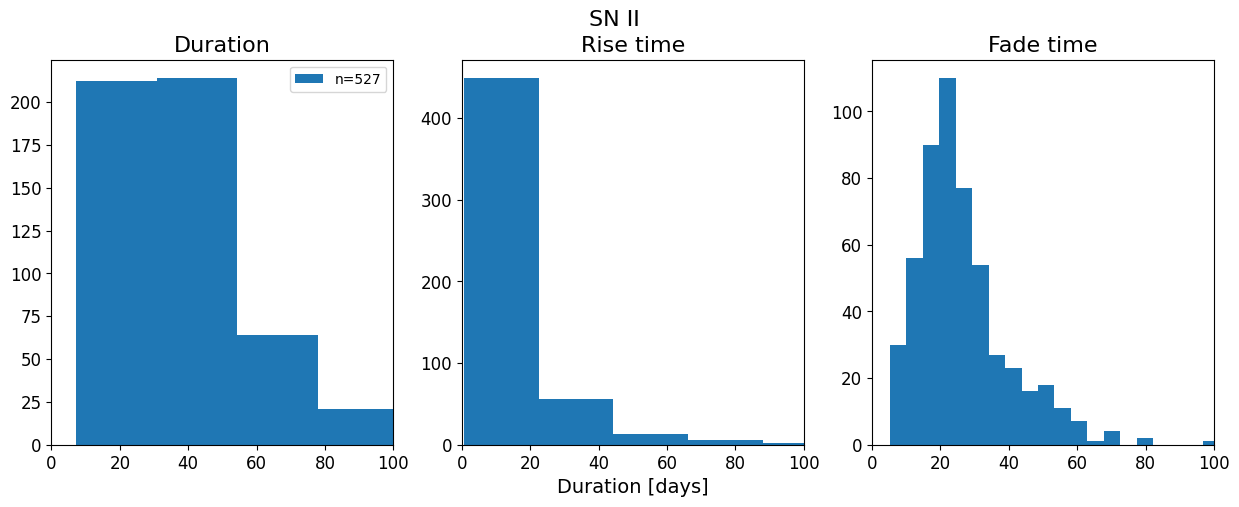

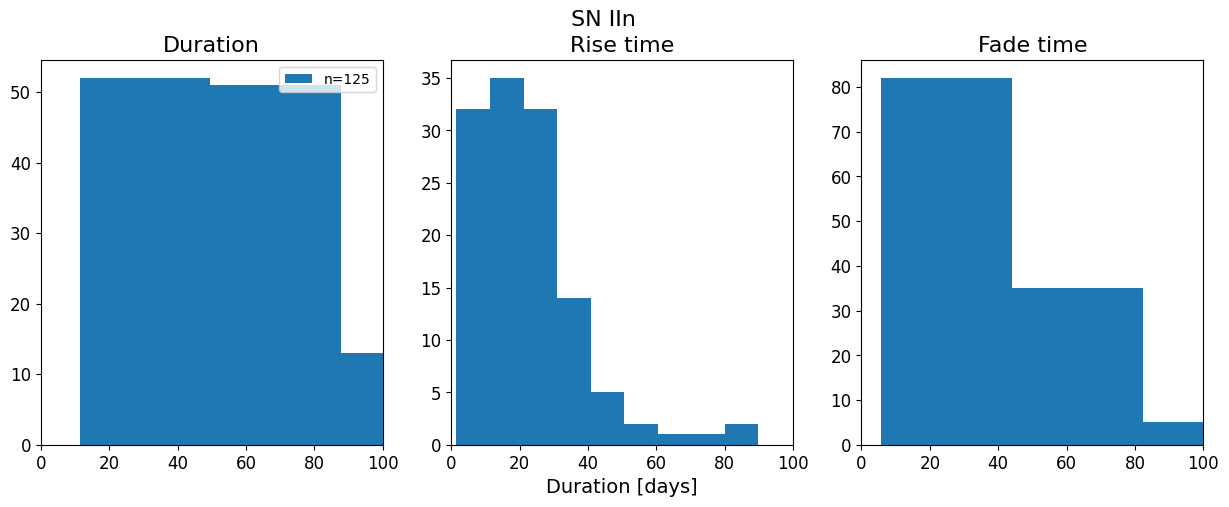

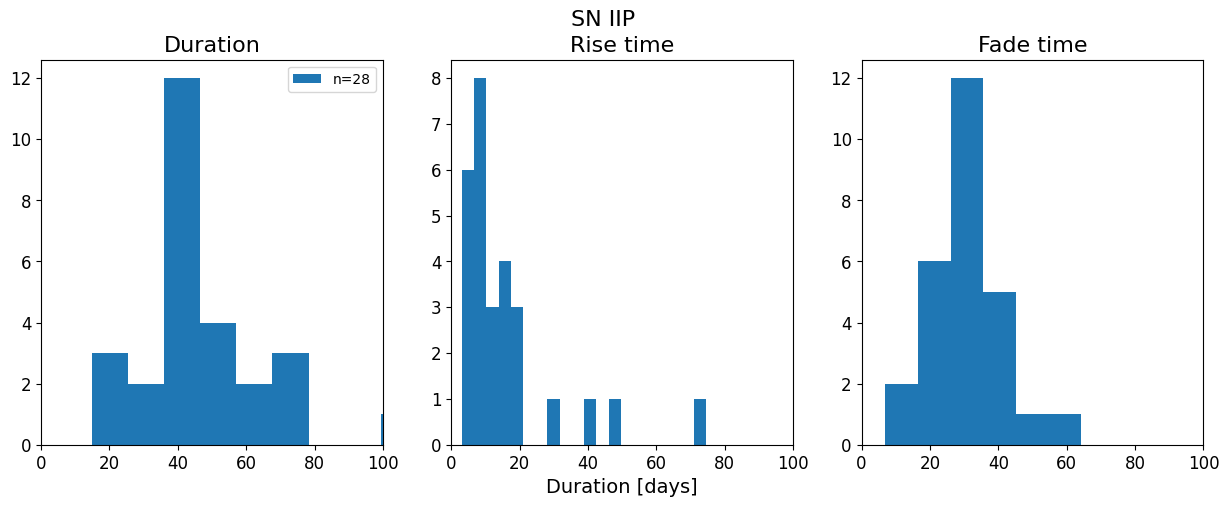

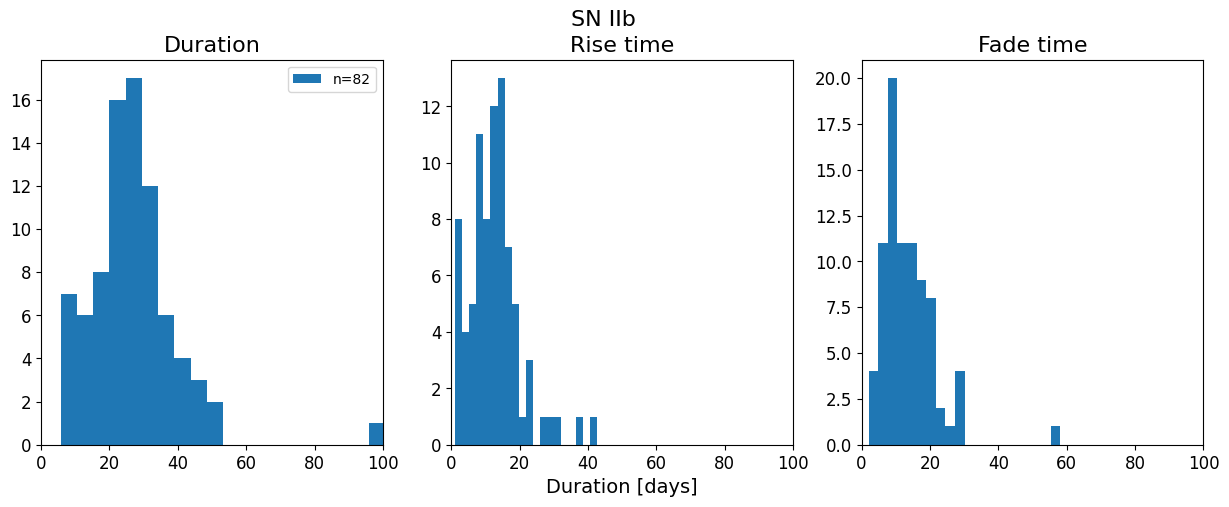

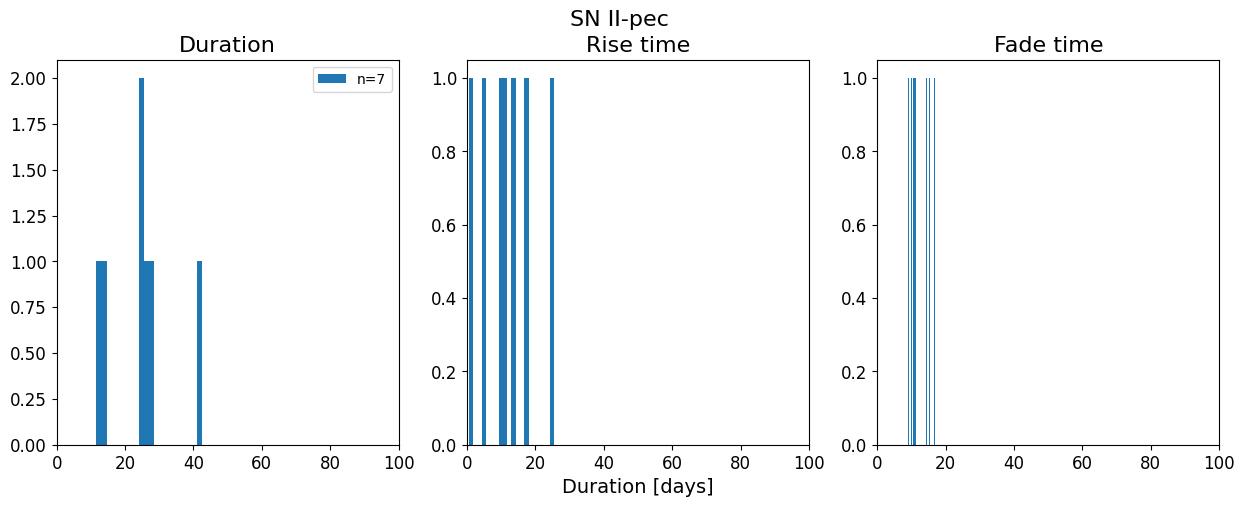

In [21]:
for key in sn_II:
    # plt.hist(times_per_type[key], label=f'n={len(times_per_type[key])}')
    # plt.title(key, fontsize=16)
    # plt.legend()
    # plt.show()
    nbins = 20
    fig, ax = plt.subplots(1, 3, figsize=(15,5))
    ax[0].hist(times_per_type[key], bins=nbins, label=f'n={len(times_per_type[key])}')
    ax[1].hist(rise_per_type[key], bins=nbins)
    ax[2].hist(fade_per_type[key], bins=nbins)
    
    ax[0].set_title('Duration', fontsize=16)
    ax[1].set_title('Rise time', fontsize=16)
    ax[2].set_title('Fade time', fontsize=16)
        
    ax[1].set_xlabel('Duration [days]', fontsize=14)
    ax[0].legend()
    for i in range(3):
        ax[i].set_xlim(0, 100)
        ax[i].tick_params(labelsize=12)
    plt.suptitle(key, fontsize=16)
    plt.show()

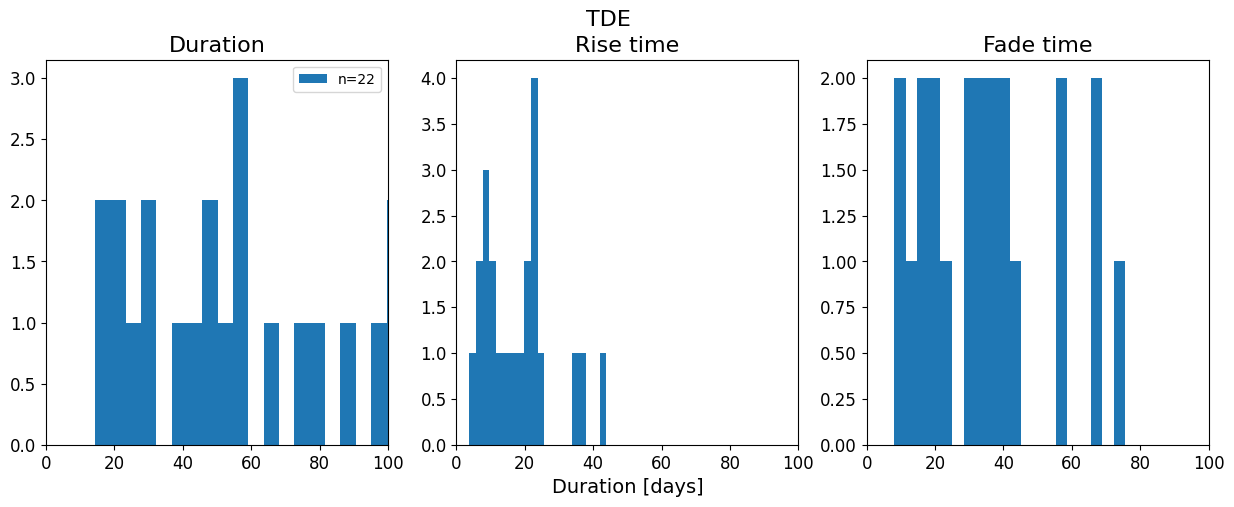

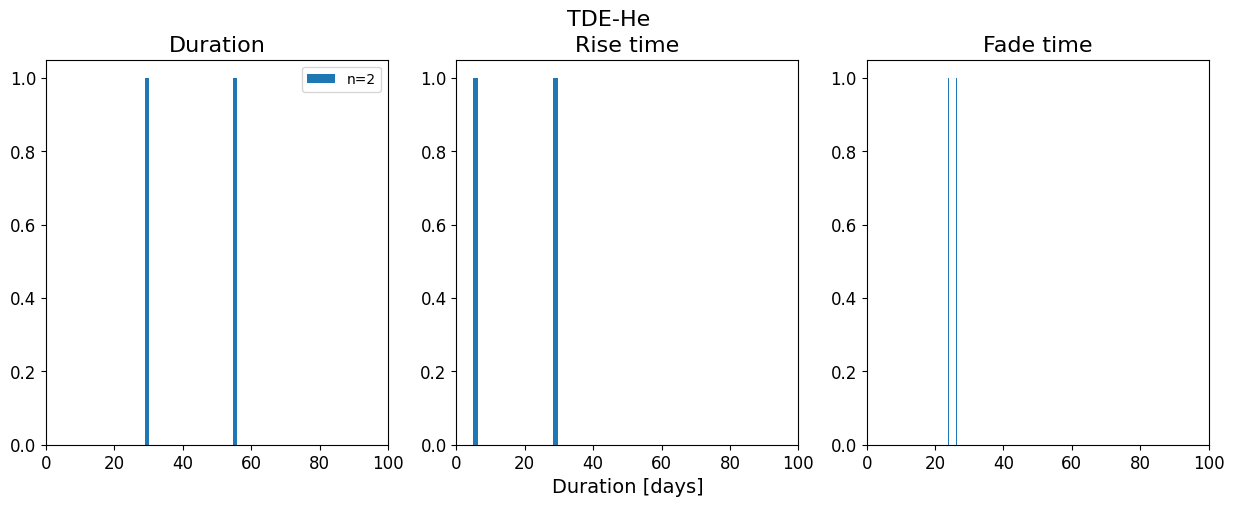

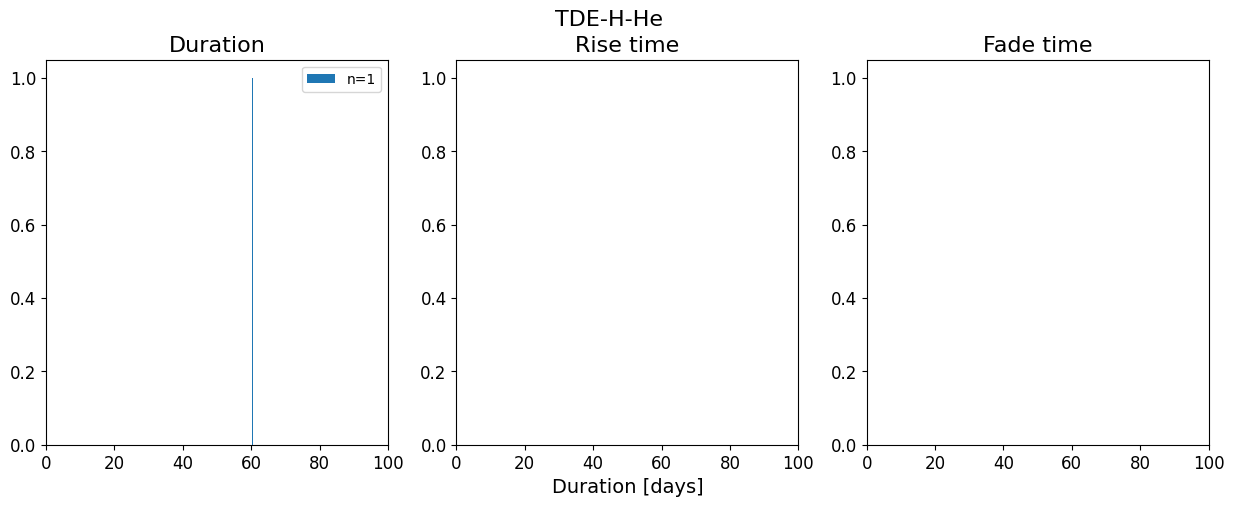

In [22]:
for key in TDE:
    # plt.hist(times_per_type[key], label=f'n={len(times_per_type[key])}')
    # plt.title(key, fontsize=16)
    # plt.legend()
    # plt.show()
    nbins = 20
    fig, ax = plt.subplots(1, 3, figsize=(15,5))
    ax[0].hist(times_per_type[key], bins=nbins, label=f'n={len(times_per_type[key])}')
    ax[1].hist(rise_per_type[key], bins=nbins)
    ax[2].hist(fade_per_type[key], bins=nbins)
    
    ax[0].set_title('Duration', fontsize=16)
    ax[1].set_title('Rise time', fontsize=16)
    ax[2].set_title('Fade time', fontsize=16)
        
    ax[1].set_xlabel('Duration [days]', fontsize=14)
    ax[0].legend()
    for i in range(3):
        ax[i].set_xlim(0, 100)
        ax[i].tick_params(labelsize=12)
    plt.suptitle(key, fontsize=16)
    plt.show()

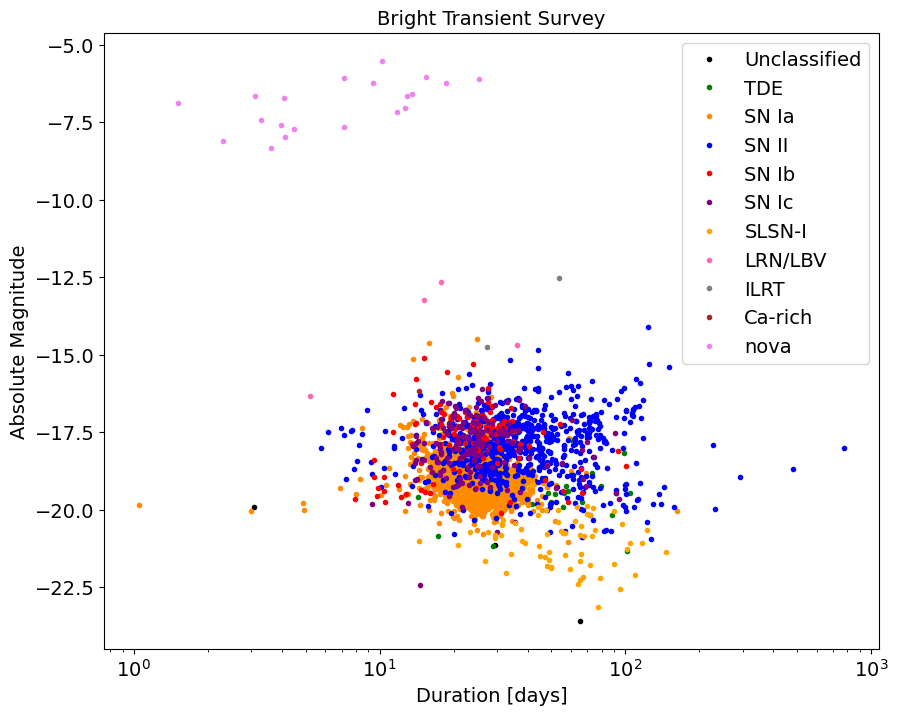

In [23]:
#Peak mag vs duration plot
colors = {
    'SN Ia': 'darkorange',
    'SN Ib': 'red',
    'SN II': 'blue',
    'TDE': 'green',
    'Unclassified': 'black', #unclasified
    'nova': 'violet',
    'SLSN-I': 'orange',
    'SLSN-II': 'lightblue',
    'LRN/LBV': 'hotpink',
    'ILRT': 'gray',
    'Ca-rich': 'brown',
    'SN Ic': 'purple'
    
}

fig = plt.figure(figsize=(10,8))

duration_index = headers.index('duration')
peakabs_index = headers.index('peakabs')
rise_index = headers.index('rise')
fade_index = headers.index('fade')

grouped_data = dict()
n = 0
for sn_type in sn_per_type.keys():
    
    if sn_type == '-' or sn_type == 'Other' or sn_type == 'other':
        label = 'Unclassified'
        c = colors[label]
        
    else:
        c, label = [(colors[key], key) for key in colors.keys() if key in sn_type or sn_type in key][0]
    duration = []
    peakabs = []
    rise = []
    fade = []
    for sn in sn_per_type[sn_type]:
        
        if '>' not in sn[duration_index] and '<' not in sn[duration_index] and sn[peakabs_index] != '-':
            duration.append(float(sn[duration_index])) 
            peakabs.append(float(sn[peakabs_index]))   
            rise.append(float(sn[rise_index]))
            fade.append(float(sn[fade_index]))
            
    if label not in grouped_data.keys():
        grouped_data[label] = [duration, peakabs, c, rise, fade]
    else:
        grouped_data[label][0].extend(duration)
        grouped_data[label][1].extend(peakabs)
        grouped_data[label][3].extend(rise)
        grouped_data[label][4].extend(fade)
    # print(sn_type, ' -> ', label)
for label in grouped_data.keys():
    plt.plot(grouped_data[label][0], grouped_data[label][1], '.',  c=grouped_data[label][2], label=label)
plt.legend(fontsize=14)
plt.xscale('log')
plt.xlabel('Duration [days]', fontsize=14)
plt.ylabel('Absolute Magnitude', fontsize=14)
plt.title('Bright Transient Survey', fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.show()
    

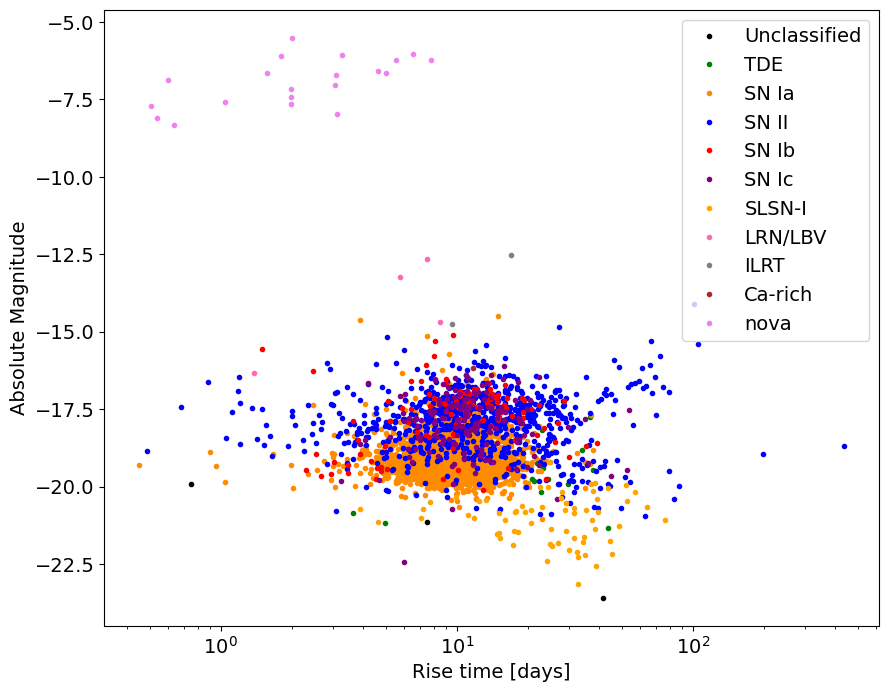

In [24]:
fig = plt.figure(figsize=(10,8))
for label in grouped_data.keys():
    plt.plot(grouped_data[label][3], grouped_data[label][1], '.',  c=grouped_data[label][2], label=label)
plt.legend(fontsize=14)
plt.xscale('log')
plt.xlabel('Rise time [days]', fontsize=14)
plt.ylabel('Absolute Magnitude', fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.show()

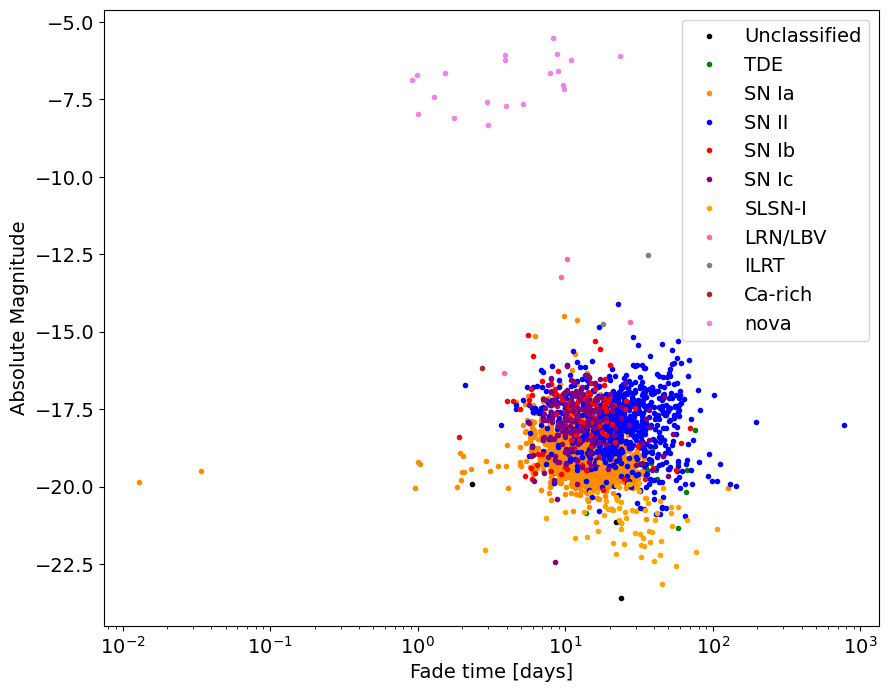

In [25]:
fig = plt.figure(figsize=(10,8))
for label in grouped_data.keys():
    plt.plot(grouped_data[label][4], grouped_data[label][1], '.',  c=grouped_data[label][2], label=label)
plt.legend(fontsize=14)
plt.xscale('log')
plt.xlabel('Fade time [days]', fontsize=14)
plt.ylabel('Absolute Magnitude', fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.show()

In [26]:
index = 6
print(sn_per_type['-'][index])
print(sn_per_type['-'][index][headers.index('fade')])
print(sn_per_type['-'][index][headers.index('duration')])
print(float(sn_per_type['-'][index][headers.index('rise')]) + float(sn_per_type['-'][index][headers.index('fade')]))


['ZTF18aaclshi', 'AT2021abbb', '08:08:56.14', '+38:53:08.6', '1503.87', 'r', '18.0491', '-', '17.77', '8.584', '9.186', '-', '-', '31.06910218', '0.132']
9.186
17.77
17.77


In [27]:
headers

['ZTFID',
 'IAUID',
 'RA',
 'Dec',
 'peakt',
 'peakfilt',
 'peakmag',
 'peakabs',
 'duration',
 'rise',
 'fade',
 'type',
 'redshift',
 'b',
 'A_V']

In [28]:
name = 'ZTF20acfucwr'
for sn_type in sn_per_type.keys():
    for sn in sn_per_type[sn_type]:
        if sn[headers.index('ZTFID')] == name:
            transient = sn
            break

In [29]:
for i in range(len(headers)):
    print(headers[i], ':', transient[i])

ZTFID : ZTF20acfucwr
IAUID : AT2020ulv
RA : 00:43:08.38
Dec : +41:08:49.9
peakt : 1123.89
peakfilt : g
peakmag : 16.952
peakabs : -7.571
duration : 3.977
rise : 1.044
fade : 2.933
type : nova
redshift : 0.00017
b : -21.69731887
A_V : 0.17


In [10]:
4*np.pi * (180 / np.pi) ** 2

41252.96124941928